# 02 · Cross-Modal Multi-Scale Contrast (paper §4.2, Eq. 4–10)

<div dir="rtl" style="text-align:right">

هدف: برای گره‌های **عادی**، نمایش متنی و نمایش گرافی باید با هم سازگار باشند. در یک batch به اندازه‌ی $N$، چهار «دید» (view) بین گراف و متن داریم:

| view | مقاله | چه چیزی با چه چیزی | scale |
|---|---|---|---|
| `nn` | Eq. 4 | $h^G_i \leftrightarrow h^T_i$ | inner-scale |
| `cc` | Eq. 5 | $\tilde h^G_i \leftrightarrow \tilde h^T_i$ | inner-scale |
| `nc` | Eq. 8 | $h^G_i \leftrightarrow \tilde h^T_i$ | inter-scale |
| `cn` | Eq. 9 | $\tilde h^G_i \leftrightarrow h^T_i$ | inter-scale |

قطر ماتریس شباهت = جفت مثبت، بقیه = منفی (Figure 1 مقاله). $\mathcal L^{cross}=\mathcal L^{inner}+\mathcal L^{inter}$ (Eq. 6, 7, 10).

</div>

In [1]:
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")      # Windows: avoid the duplicate-OpenMP abort that kills the kernel
import faulthandler; faulthandler.enable()          # prints a native traceback to the Jupyter log if the kernel dies
import sys, json, time
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch, torch.nn.functional as F
from torch.utils.data import DataLoader
from cmucl_nb import common as C, views as V

cfg = C.load_config(); args = C.as_args(cfg); device = C.get_device(cfg)
C.set_cpu_threads()                          # leave some CPU cores free so the laptop stays responsive
C.fetch_official_code()                      # official repo -> ./third_party/CMUCL (not copied into this repo)
from model import CMUCL, tokenize            # official model + tokenizer
from data import DataHelper                  # official neighbour sampler

ds = C.load_saved_dataset()
x = torch.from_numpy(ds["feats"]).to(device)
edge_index = torch.from_numpy(ds["edge_index"]).to(device)
labels, texts = ds["labels"], ds["texts"]
print(f"dataset={cfg['dataset']}  device={device}  torch threads={torch.get_num_threads()}  nodes={ds['n']} (of {cfg.get('n_full')})  anomalies={labels.sum()}")

dataset=Citeseer  device=cpu  torch threads=4  nodes=384 (of 3186)  anomalies=19


In [2]:
model = CMUCL(args).to(device); C.prepare_model(model)   # CPU: thread limit + gradient checkpointing (same maths, far less RAM)
model.load_state_dict(torch.load(C.ART / "init_state.pt", map_location=device)); model.eval()
probe = V.load_probe(C.ART, texts, tokenize, args.context_length, device)
feats, logits = V.probe_logits(model, x, edge_index, probe, args.neigh_num)
scale = float(model.logit_scale.exp()); B = len(probe[0])
anom_pos = np.where(labels[probe[0].numpy()] == 1)[0]
print(f"batch N={B}, anomalous nodes in batch: {len(anom_pos)}, logit_scale={scale:.2f} (tau={1/scale:.3f}; paper tau=0.07)")

batch N=64, anomalous nodes in batch: 2, logit_scale=14.29 (tau=0.070; paper tau=0.07)


C:\Users\KimiaMalekizadeh\AppData\Local\Temp\ipykernel_1060\1631164772.py:5: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  scale = float(model.logit_scale.exp()); B = len(probe[0])


<div dir="rtl" style="text-align:right">

## چهار ماتریس شباهت (cosine)
مثلث قرمز = گره ناهنجار در این batch. روی مدل آموزش‌ندیده قطر **نباید** برجسته باشد.

</div>

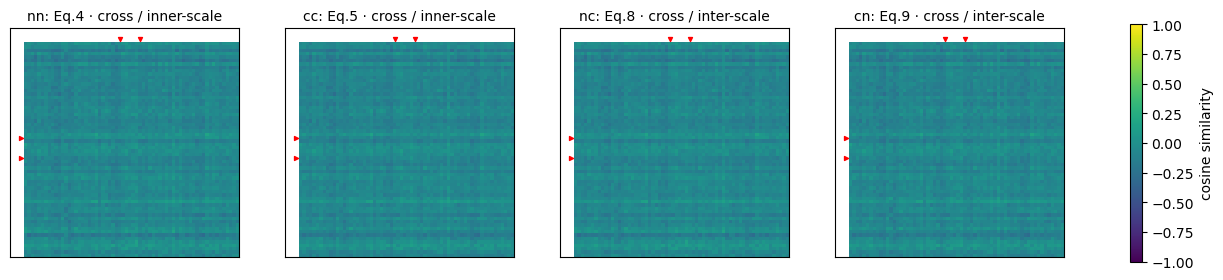

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4))
for a, k in zip(ax, V.CROSS):
    im = V.plot_cos(a, logits[k], scale, f"{k}: {V.VIEW_INFO[k]['eq']} · {V.VIEW_INFO[k]['kind']}", anom_pos)
fig.colorbar(im, ax=ax, shrink=.7, label="cosine similarity"); C.savefig("02_cross_modal_matrices_init"); plt.show()

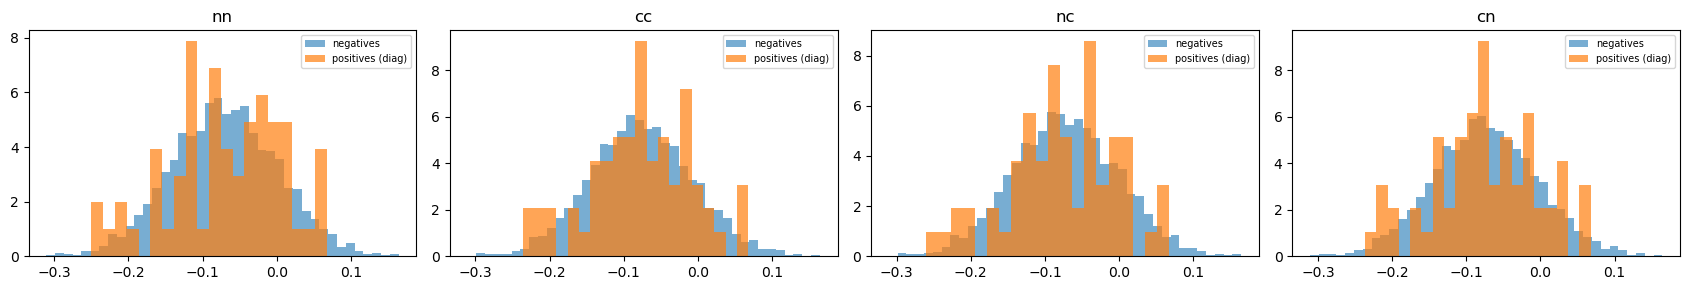

In [4]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3))
for a, k in zip(ax, V.CROSS):
    M = (logits[k] / scale).cpu().numpy(); off = M[~np.eye(B, dtype=bool)]
    a.hist(off, bins=40, alpha=.6, density=True, label="negatives"); a.hist(np.diag(M), bins=20, alpha=.7, density=True, label="positives (diag)")
    a.set_title(k); a.legend(fontsize=7)
plt.tight_layout(); C.savefig("02_pos_neg_hist_init"); plt.show()

<div dir="rtl" style="text-align:right">

## Loss هر view
کد رسمی از InfoNCE **دوطرفه** استفاده می‌کند: $(\text{CE}_{rows}+\text{CE}_{cols})/2$ با دمای **قابل یادگیری** ($\tau$ از $1/0.07$ شروع می‌شود)؛ فرمول Eq. 4 مقاله فقط یک جهت دارد. هر دو را محاسبه می‌کنم تا تفاوت شفاف باشد.

</div>

In [5]:
L_code = V.view_losses(logits)
rows = {k: dict(eq=V.VIEW_INFO[k]["eq"], scale=V.VIEW_INFO[k]["kind"], loss_code_symmetric=float(L_code[k]),
                loss_paper_one_direction=float(V.infonce_paper(logits[k])),
                top1_acc=float((logits[k].argmax(1).cpu() == torch.arange(B)).float().mean())) for k in V.CROSS}
tbl = pd.DataFrame(rows).T; display(tbl)
inner = L_code["nn"] + L_code["cc"]; inter = L_code["nc"] + L_code["cn"]
print(f"L_inner (Eq.6) = {float(inner):.4f} | L_inter (Eq.7) = {float(inter):.4f} | L_cross (Eq.10) = {float(inner+inter):.4f} | random-guess CE = ln({B}) = {np.log(B):.4f}")
json.dump(dict(inner=float(inner), inter=float(inter), cross=float(inner + inter), views={k: float(v) for k, v in L_code.items()}),
          open(C.ART / "stage02.json", "w"), indent=1)

,eq,scale,loss_code_symmetric,loss_paper_one_direction,top1_acc
nn,Eq.4,cross / inner-scale,4.491004,4.390059,0.0
cc,Eq.5,cross / inner-scale,4.489534,4.3886,0.0
nc,Eq.8,cross / inter-scale,4.519331,4.410119,0.0
cn,Eq.9,cross / inter-scale,4.495222,4.40182,0.0


L_inner (Eq.6) = 8.9805 | L_inter (Eq.7) = 9.0146 | L_cross (Eq.10) = 17.9951 | random-guess CE = ln(64) = 4.1589


`top1_acc` = fraction of nodes whose true partner is the most similar one in the batch (chance ≈ 1/N). It is the quantity contrastive training pushes up for normal nodes.